In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

In [50]:
df = pd.read_csv("/Users/fesavaskurt/Python&ML/Kodlarım/Python/datasets/ML Datasets/bank+marketing/bank-additional/bank-additional-full.csv", sep = ";")

In [18]:
df.shape

(41188, 21)

In [19]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

In [72]:
df.isnull().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

In [73]:
df["y"].value_counts()

y
no     36548
yes     4640
Name: count, dtype: int64

In [74]:
df["y"].value_counts(normalize= True)

y
no     0.887346
yes    0.112654
Name: proportion, dtype: float64

In [76]:
object_col = df.select_dtypes("object")

In [77]:
num_col = df.select_dtypes(exclude=["object"])

In [79]:
num_col.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [93]:
for i in object_col.columns:
    print("-"*20)
    print("unique değer sayısı:", object_col[i].nunique())
    print(object_col[i].value_counts(normalize= True))

--------------------
unique değer sayısı: 12
job
admin.           0.253035
blue-collar      0.224677
technician       0.163713
services         0.096363
management       0.070992
retired          0.041760
entrepreneur     0.035350
self-employed    0.034500
housemaid        0.025736
unemployed       0.024619
student          0.021244
unknown          0.008012
Name: proportion, dtype: float64
--------------------
unique değer sayısı: 4
marital
married     0.605225
single      0.280859
divorced    0.111974
unknown     0.001942
Name: proportion, dtype: float64
--------------------
unique değer sayısı: 8
education
university.degree      0.295426
high.school            0.231014
basic.9y               0.146766
professional.course    0.127294
basic.4y               0.101389
basic.6y               0.055647
unknown                0.042027
illiterate             0.000437
Name: proportion, dtype: float64
--------------------
unique değer sayısı: 3
default
no         0.791201
unknown    0.208726
ye

In [104]:
df[df.duplicated(keep= False)]

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
1265,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
1266,39,blue-collar,married,basic.6y,no,no,no,telephone,may,thu,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
12260,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
12261,36,retired,married,unknown,no,no,no,telephone,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.966,5228.1,no
14155,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
14234,27,technician,single,professional.course,no,no,no,cellular,jul,mon,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
16819,47,technician,divorced,high.school,no,yes,no,cellular,jul,thu,...,3,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
16956,47,technician,divorced,high.school,no,yes,no,cellular,jul,thu,...,3,999,0,nonexistent,1.4,93.918,-42.7,4.962,5228.1,no
18464,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no
18465,32,technician,single,professional.course,no,yes,no,cellular,jul,thu,...,1,999,0,nonexistent,1.4,93.918,-42.7,4.968,5228.1,no


In [109]:
for i in df.columns:
    print(i)
    print(df[i].shape)

age
(41188,)
job
(41188,)
marital
(41188,)
education
(41188,)
default
(41188,)
housing
(41188,)
loan
(41188,)
contact
(41188,)
month
(41188,)
day_of_week
(41188,)
duration
(41188,)
campaign
(41188,)
pdays
(41188,)
previous
(41188,)
poutcome
(41188,)
emp.var.rate
(41188,)
cons.price.idx
(41188,)
cons.conf.idx
(41188,)
euribor3m
(41188,)
nr.employed
(41188,)
y
(41188,)


In [112]:
cat_cols = df.select_dtypes("object")

In [163]:
def_un = cat_cols["default"] == "unknown"

In [164]:
def_un.sum()

np.int64(8597)

In [165]:
def_un.mean()

np.float64(0.20872584247839177)

In [ ]:
unknown_list = []
for i in cat_cols:
    un_col = cat_cols[i] == "unknown"
    if un_col.sum() > 0:
        unknown = {
            "sütun": i,
            "toplam_kayıt":len(cat_cols),
            "unknown_sayısı": un_col.sum(),
            "unknown_yüzde": un_col.mean()*100 
        }
        unknown_list.append(unknown)
    


In [190]:
pd.DataFrame(unknown_list).sort_values(by = "unknown_yüzde", ascending= False)

,sütun,toplam_kayıt,unknown_sayısı,unknown_yüzde
3,default,41188,8597,20.872584
2,education,41188,1731,4.202680
4,housing,41188,990,2.403613
5,loan,41188,990,2.403613
0,job,41188,330,0.801204
1,marital,41188,80,0.194231


In [194]:
housing_unknown = df["housing"] == "unknown"
loan_unknown = df["loan"] == "unknown"

In [195]:
pd.crosstab(housing_unknown, loan_unknown)

loan,False,True
housing,,
False,40198,0
True,0,990


In [197]:
pdays_stats = df["pdays"] == 999

In [198]:
pdays_stats.sum()

np.int64(39673)

In [204]:
pdays_stats.mean()*100

np.float64(96.32174419733903)

In [202]:
pdays_stats_v1 = df[df["pdays"] != 999]

In [203]:
pdays_stats_v1.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,1515.000000,1515.000000,1515.000000,1515.000000,1515.000000,1515.000000,1515.000000,1515.000000,1515.000000,1515.000000
mean,41.852805,321.485809,1.822442,6.014521,1.660726,-2.096238,93.342507,-38.341386,0.985949,5029.244686
std,15.296112,254.676128,1.241414,3.824906,0.934306,0.833032,0.783216,6.628399,0.533622,52.308986
min,17.000000,1.000000,1.000000,0.000000,1.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,30.000000,165.000000,1.000000,3.000000,1.000000,-2.900000,92.649000,-42.000000,0.718000,4991.600000
50%,37.000000,253.000000,1.000000,6.000000,1.000000,-1.800000,93.200000,-38.300000,0.879000,5017.500000
75%,52.000000,392.000000,2.000000,7.000000,2.000000,-1.700000,94.055000,-31.400000,1.044000,5076.200000
max,98.000000,3509.000000,13.000000,27.000000,7.000000,-0.100000,94.767000,-26.900000,4.286000,5195.800000


In [205]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [207]:
previous_stats = df["previous"] == 0

In [213]:
pd.crosstab(pdays_stats, df["poutcome"])

poutcome,failure,nonexistent,success
pdays,,,
False,142,0,1373
True,4110,35563,0


In [212]:
df.groupby("pdays")["previous"].count()

pdays
0         15
1         26
2         61
3        439
4        118
5         46
6        412
7         60
8         18
9         64
10        52
11        28
12        58
13        36
14        20
15        24
16        11
17         8
18         7
19         3
20         1
21         2
22         3
25         1
26         1
27         1
999    39673
Name: previous, dtype: int64

In [215]:
df["campaign"].value_counts()

campaign
1     17642
2     10570
3      5341
4      2651
5      1599
6       979
7       629
8       400
9       283
10      225
11      177
12      125
13       92
14       69
17       58
16       51
15       51
18       33
20       30
19       26
21       24
22       17
23       16
24       15
27       11
29       10
28        8
26        8
25        8
31        7
30        7
35        5
32        4
33        4
34        3
42        2
40        2
43        2
56        1
39        1
41        1
37        1
Name: count, dtype: int64

In [217]:
df["age"].describe()

count    41188.00000
mean        40.02406
std         10.42125
min         17.00000
25%         32.00000
50%         38.00000
75%         47.00000
max         98.00000
Name: age, dtype: float64

Text(0, 0.5, 'Adet')

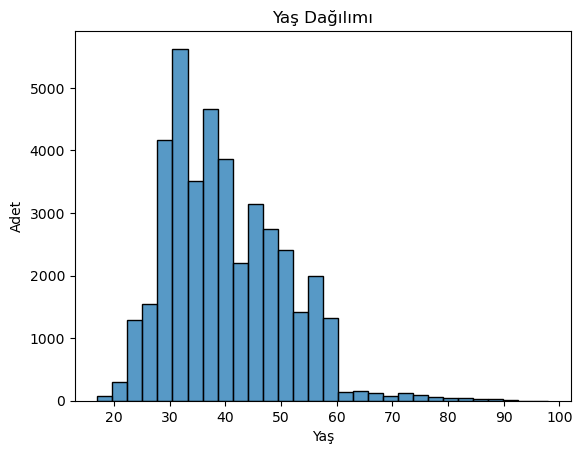

In [224]:
sns.histplot(df["age"], bins= 30)
plt.title("Yaş Dağılımı")
plt.xlabel("Yaş")
plt.ylabel("Adet")

In [ ]:
df.groupby("y")["age"].mean()

y
no     39.911185
yes    40.913147
Name: age, dtype: float64

In [227]:
pd.cut(df["age"], bins=[0,30,39,40,49,50,59,60])

0        (50.0, 59.0]
1        (50.0, 59.0]
2        (30.0, 39.0]
3        (39.0, 40.0]
4        (50.0, 59.0]
             ...     
41183             NaN
41184    (40.0, 49.0]
41185    (50.0, 59.0]
41186    (40.0, 49.0]
41187             NaN
Name: age, Length: 41188, dtype: category
Categories (7, interval[int64, right]): [(0, 30] < (30, 39] < (39, 40] < (40, 49] < (49, 50] < (50, 59] < (59, 60]]

In [269]:
age_def_table = pd.crosstab(pd.cut(df["age"], bins=[0,30,40,50,60, np.inf], right= False),df["y"])

In [270]:
age_def_table["oran"] = age_def_table["yes"] / (age_def_table["yes"] + age_def_table["no"])*100

In [271]:
age_def_table

y,no,yes,oran
age,,,
"[0.0, 30.0)",4747,922,16.263891
"[30.0, 40.0)",15223,1715,10.125162
"[40.0, 50.0)",9692,834,7.923238
"[50.0, 60.0)",6165,697,10.157389
"[60.0, inf)",721,472,39.564124


In [272]:
df["job"].shape

(41188,)

In [277]:
df["y"] = (df["y"] == "yes").astype(int)

In [284]:
job_def = df.groupby("job")["y"].agg(["mean", "sum", "size"])

In [286]:
job_def["mean"] = job_def["mean"]*100

In [288]:
job_def = job_def.sort_values(by = "mean", ascending= False)

In [289]:
job_def

,mean,sum,size
job,,,
student,31.428571,275,875
retired,25.232558,434,1720
unemployed,14.201183,144,1014
admin.,12.972558,1352,10422
management,11.217510,328,2924
unknown,11.212121,37,330
technician,10.826042,730,6743
self-employed,10.485574,149,1421
housemaid,10.000000,106,1060


In [291]:
analysis_df = df[["age", "job", "y"]].copy()

target_mapping = {"yes": 1, "no": 0, 1: 1, 0: 0}
analysis_df["target"] = analysis_df["y"].map(target_mapping)

if analysis_df["target"].isna().any():
    raise ValueError("Target sütununda beklenmeyen veya eksik değer var.")

age_labels = ["30 altı", "30–39", "40–49", "50–59", "60 ve üzeri"]

analysis_df["age_group"] = pd.cut(
    analysis_df["age"],
    bins=[0, 30, 40, 50, 60, np.inf],
    labels=age_labels,
    right=False
)

age_job_summary = (
    analysis_df
    .groupby(["age_group", "job"], observed=True)
    .agg(
        total_count=("target", "size"),
        subscriber_count=("target", "sum"),
        subscription_rate=("target", "mean")
    )
    .reset_index()
)

age_job_summary["subscription_pct"] = (
    age_job_summary["subscription_rate"] * 100
)

age_job_focus = (
    age_job_summary.loc[
        age_job_summary["age_group"].isin(["50–59", "60 ve üzeri"]),
        ["age_group", "job", "total_count",
         "subscriber_count", "subscription_pct"]
    ]
    .sort_values(
        ["age_group", "subscription_pct"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

age_job_focus.round({"subscription_pct": 2})

,age_group,job,total_count,subscriber_count,subscription_pct
0,50–59,unemployed,170,24,14.12
1,50–59,admin.,1325,179,13.51
2,50–59,retired,826,95,11.50
3,50–59,technician,906,98,10.82
4,50–59,management,703,76,10.81
5,50–59,unknown,92,9,9.78
6,50–59,housemaid,323,30,9.29
7,50–59,blue-collar,1416,111,7.84
8,50–59,entrepreneur,319,24,7.52
9,50–59,self-employed,268,19,7.09


In [304]:
df.groupby("default")["y"].agg(["mean", "sum", "size"])

,mean,sum,size
default,,,
no,0.12879,4197,32588
unknown,0.05153,443,8597
yes,0.00000,0,3


In [327]:
df.groupby("month")["y"].agg(
    ortalama = "mean", 
    toplam_kayıt = "size",
    toplam_abone = "sum"
    ).sort_values(by = "toplam_abone", ascending= False)

,ortalama,toplam_kayıt,toplam_abone
month,,,
may,0.064347,13769,886
aug,0.106021,6178,655
jul,0.090466,7174,649
jun,0.105115,5318,559
apr,0.204787,2632,539
nov,0.101439,4101,416
oct,0.438719,718,315
mar,0.505495,546,276
sep,0.449123,570,256


In [333]:
poutcame_analysis = df.groupby("poutcome")["y"].agg(
    ortalama = "mean", 
    toplam_kayıt = "size",
    toplam_abone = "sum"
    ).sort_values(by = "ortalama", ascending= False)

In [334]:
poutcame_analysis

,ortalama,toplam_kayıt,toplam_abone
poutcome,,,
success,0.651129,1373,894
failure,0.142286,4252,605
nonexistent,0.088322,35563,3141


In [351]:
poutcame_analysis.iloc[0][1] / poutcame_analysis["toplam_kayıt"].sum()

/var/folders/sj/pj9lwv9d1r17b6cggf8ym3gc0000gn/T/ipykernel_71348/1632808019.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  poutcame_analysis.iloc[0][1] / poutcame_analysis["toplam_kayıt"].sum()


np.float64(0.033334951927745944)

In [352]:
poutcame_analysis.iloc[0][2] / poutcame_analysis["toplam_abone"].sum()

/var/folders/sj/pj9lwv9d1r17b6cggf8ym3gc0000gn/T/ipykernel_71348/3701783998.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  poutcame_analysis.iloc[0][2] / poutcame_analysis["toplam_abone"].sum()


np.float64(0.19267241379310346)